In [46]:
import numpy as np
import matplotlib.pyplot as plt
import random
import scipy
from scipy.stats import multivariate_normal


# Sorry for the typos in advance

print("Installations Working!")

Installations Working!


# Question 1.a

In [39]:
# Parameter Definitions

class_0_prior = .35
class_1_prior = .65

# Establishing Distrabutions
rng = np.random.default_rng(0)


L = (rng.random(10000) < class_1_prior).astype(int)   # 1 with prob 0.65, else 0
n1 = np.sum(L == 1)
n0 = np.sum(L == 0)


dist_0_mu = [-.5, -.5, -.5, -.5]
dist_0_cov = [[.5,   -.125, .075, 0],
              [-.125, .25, -.125, 0],
              [.075, -.125, .25,  0],
              [0, 0, 0,          .5]]

dist_1_mu = [1, 1, 1, 1]
dist_1_cov = [[1, .3, -.2,  0],
              [.3, 2, .3,   0],
              [-.2, .3, 1,  0],
              [0, 0, 0,     3]]


dist_1 = rng.multivariate_normal(dist_1_mu, dist_1_cov, size=n1)
dist_0 = rng.multivariate_normal(dist_0_mu, dist_0_cov, size=n0)

X_dist = np.vstack([dist_0, dist_1])
L = np.concatenate([np.zeros(n0, dtype=int), np.ones(n1, dtype=int)])

# Verification

print(f"Dist: {X_dist} | Shape: {X_dist.shape}")
print(f"Mean: {np.mean(X_dist)} | {np.mean(X_dist[L == 0], axis=0)} | {np.mean(X_dist[L == 1], axis=0)}")
print(f"Labels: {np.mean(L)} | Shape: {L.shape}")




Dist: [[-0.38905238 -0.55240113 -0.34596905  0.35145531]
 [-1.22069041 -0.43139681 -0.38428479 -0.10591616]
 [-0.25287176 -0.81507532 -0.62663037 -0.16800769]
 ...
 [ 1.23283647 -1.00302292  0.24577834  1.22254755]
 [ 2.31357911 -0.5036045  -0.10105706  2.2385587 ]
 [ 2.80521615  1.84655706  1.10396979  0.66079807]] | Shape: (10000, 4)
Mean: 0.4685589099130325 | [-0.51010748 -0.51785944 -0.49502428 -0.52404293] | [0.99694529 0.99574356 1.00816526 1.02031011]
Labels: 0.6462 | Shape: (10000,)


## Question 1.A


Best Theoretical Error: 
Gamma: 0.5384615384615384
TPR: 0.9732281027545652 FPR: 0.026568682871678916
Best Estimated Error: 
Gamma: -0.47946717763079505
TPR: 0.9727638502011761 FPR: 0.022894290559638215 


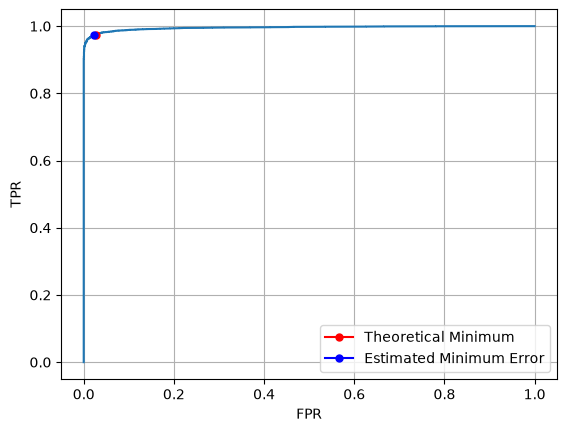

In [40]:
# ROC Curve Building

q1_scores = (multivariate_normal(dist_1_mu, dist_1_cov).logpdf(X_dist) - multivariate_normal(dist_0_mu, dist_0_cov).logpdf(X_dist))
thresholds = np.concatenate([[-np.inf], np.sort(q1_scores), [np.inf]])

TPR, FPR = [], []

Gamma_map = dict()

for threshold in thresholds:
    Decision = q1_scores > threshold
    TPR.append(np.mean(Decision[L == 1])) # P(D=1 | L=1)
    FPR.append(np.mean(Decision[L == 0])) # P(D=1 | L=0)
    Gamma_map[threshold] = (np.mean(Decision[L == 1]), np.mean(Decision[L == 0]))

plt.plot(FPR, TPR)

# Theoretical Building of the Lowest Error

P_error = class_0_prior / class_1_prior  # Theoretical lowest
Decision = q1_scores > np.log(P_error)
theoretical_full_fpr = float(np.mean(Decision[L == 0]))
theoretical_full_tpr = float(np.mean(Decision[L == 1]))
print(f"Best Theoretical Error: ")
print(f"Gamma: {P_error}")
print(f"TPR: {theoretical_full_tpr} FPR: {theoretical_full_fpr}")

plt.plot(theoretical_full_fpr,theoretical_full_tpr, color='red', marker='o', markersize=5, label='Theoretical Minimum')

# Estimation of Lowest Error

error = np.inf
for t in thresholds:
    tpr, fpr = Gamma_map[t] 
    new_error = fpr * class_0_prior + (1-tpr) * class_1_prior

    if new_error < error:
        error = new_error
        best_gamma = t
        best_full_tpr = tpr
        best_full_fpr = fpr

print(f"Best Estimated Error: ")
print(f"Gamma: {best_gamma}")
print(f"TPR: {best_full_tpr} FPR: {best_full_fpr} ")

plt.plot(best_full_fpr, best_full_tpr, marker='o', markersize=5, color='blue', label='Estimated Minimum Error')

plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.grid(True)
plt.show()



## Question 1.B- Naive Bayes Classifier

Best Theoretical Error: 
Gamma: 0.5384615384615384
TPR: 0.8935314144227793 FPR: 0.007631430186546071
Best Estimated Error: 
Gamma: -1.8194851754047026
TPR: 0.9382544103992572 FPR: 0.041831543244771056 


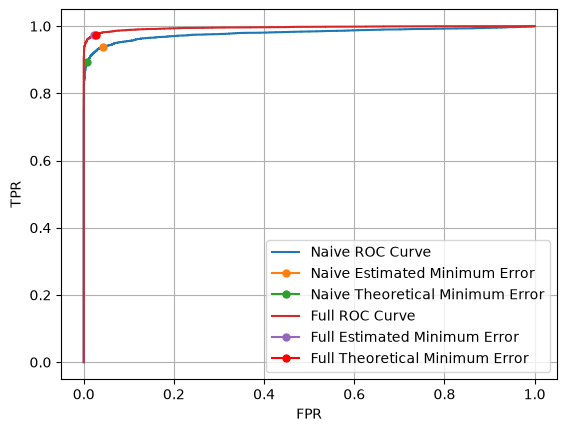

In [41]:
# ROC Curve Building

q2_score = (multivariate_normal(dist_1_mu).logpdf(X_dist) - multivariate_normal(dist_0_mu).logpdf(X_dist))
thresholds = np.concatenate([[-np.inf], np.sort(q2_score), [np.inf]])

TPR_naive, FPR_naive = [], []

Gamma_map_naive = dict()

for threshold in thresholds:
    Decision = q2_score > threshold
    TPR_naive.append(np.mean(Decision[L == 1])) # P(D=1 | L=1)
    FPR_naive.append(np.mean(Decision[L == 0])) # P(D=1 | L=0)
    Gamma_map_naive[threshold] = (np.mean(Decision[L == 1]), np.mean(Decision[L == 0]))


# Theoretical Building of the Lowest Error

P_error = class_0_prior / class_1_prior  # Theoretical lowest
Decision = q2_score > np.log(P_error)
theoretical_naive_fpr = float(np.mean(Decision[L == 0]))
theoretical_naive_tpr = float(np.mean(Decision[L == 1]))
print(f"Best Theoretical Error: ")
print(f"Gamma: {P_error}")
print(f"TPR: {theoretical_naive_tpr} FPR: {theoretical_naive_fpr}")


# Estimation of Lowest Erro

error = np.inf
for t in thresholds:
    tpr, fpr = Gamma_map_naive[t] 
    new_error = fpr * class_0_prior + (1-tpr) * class_1_prior

    if new_error < error:
        error = new_error
        best_gamma = t
        best_tpr_naive = tpr
        best_fpr_naive = fpr

print(f"Best Estimated Error: ")
print(f"Gamma: {best_gamma}")
print(f"TPR: {best_tpr_naive} FPR: {best_fpr_naive} ")


# Plotting of the Naive Bayseian Classifier
plt.plot(FPR_naive, TPR_naive, label="Naive ROC Curve")
plt.plot(best_fpr_naive, best_tpr_naive, marker='o', markersize=5, label='Naive Estimated Minimum Error')
plt.plot(theoretical_naive_fpr, theoretical_naive_tpr, marker='o', markersize=5, label='Naive Theoretical Minimum Error')




# Full Bayseian Classifer for comparison
plt.plot(FPR, TPR, label="Full ROC Curve")
plt.plot(best_full_fpr, best_full_tpr, marker='o', markersize=5, label='Full Estimated Minimum Error')
plt.plot(theoretical_full_fpr,theoretical_full_tpr, color='red', marker='o', markersize=5, label='Full Theoretical Minimum Error')


plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.grid(True)
plt.show()



# Question 1.C- Fisher LDA

Mu_0: [-0.51010748 -0.51785944 -0.49502428 -0.52404293]
Mu_1: [0.99694529 0.99574356 1.00816526 1.02031011]
Cov_0: [[ 5.07612699e-01 -1.31460020e-01  7.63287129e-02 -7.34899860e-03]
 [-1.31460020e-01  2.61940671e-01 -1.30316669e-01  1.00945041e-03]
 [ 7.63287129e-02 -1.30316669e-01  2.48613251e-01 -1.56326508e-04]
 [-7.34899860e-03  1.00945041e-03 -1.56326508e-04  4.99484639e-01]]
Cov_1: [[ 1.00032281e+00  3.15774982e-01 -1.91256619e-01  1.76906550e-02]
 [ 3.15774982e-01  1.99401459e+00  3.13224742e-01  1.02799041e-03]
 [-1.91256619e-01  3.13224742e-01  1.01161823e+00 -1.96562652e-02]
 [ 1.76906550e-02  1.02799041e-03 -1.96562652e-02  2.99496793e+00]]
[0.46934309 0.22200944 0.5572835  0.20301962]
Best Estimated Error: 
Gamma: 0.027064776228605758
TPR: 0.9480037140204272 FPR: 0.04324477105709441 


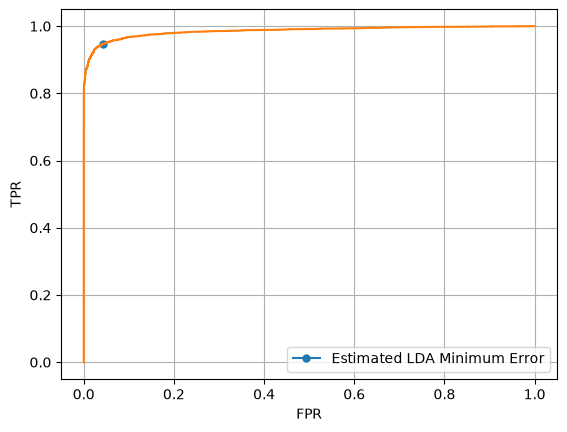

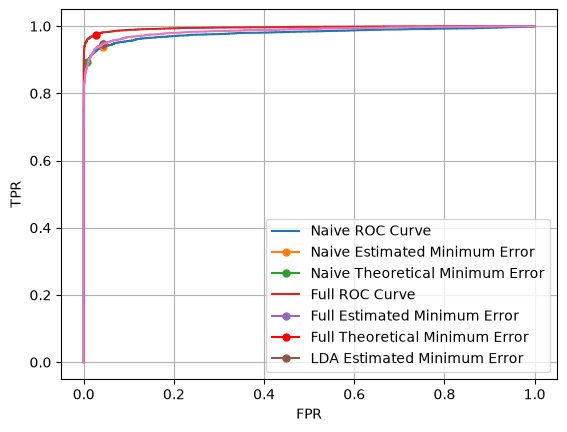

In [67]:
X_dist = np.vstack([dist_0, dist_1])
L = np.concatenate([np.zeros(n0, dtype=int), np.ones(n1, dtype=int)])

# Estimate the Covariance and the Mean

est_mu_0 = np.mean(X_dist[L==0], axis=0)
est_mu_1 = np.mean(X_dist[L==1], axis=0)
est_cov_0 = np.cov(X_dist[L==0], rowvar=False)
est_cov_1 = np.cov(X_dist[L==1], rowvar=False)

print(f"Mu_0: {est_mu_0}")
print(f"Mu_1: {est_mu_1}")
print(f"Cov_0: {est_cov_0}")
print(f"Cov_1: {est_cov_1}")


# Between Class Scatter
S_B = np.outer(est_mu_1 - est_mu_0, est_mu_1 - est_mu_0)

# Within Class Scatter
S_W = est_cov_0 + est_cov_1

Evals, Evects = scipy.linalg.eigh(S_B, S_W)

w_LDA = Evects[:, -1]

print(w_LDA)

score_LDA = X_dist @ w_LDA

lda_thresholds = np.concatenate([[-np.inf], np.sort(score_LDA), [np.inf]])

TPR_LDA, FPR_LDA = [], []

Gamma_map_LDA = dict()

for threshold in lda_thresholds:
    Decision = score_LDA > threshold
    TPR_LDA.append(np.mean(Decision[L == 1])) # P(D=1 | L=1)
    FPR_LDA.append(np.mean(Decision[L == 0])) # P(D=1 | L=0)
    Gamma_map_LDA[threshold] = (np.mean(Decision[L == 1]), np.mean(Decision[L == 0]))

# Estimation of Lowest Error

error = np.inf
for t in lda_thresholds:
    tpr, fpr = Gamma_map_LDA[t] 
    new_error = fpr * class_0_prior + (1-tpr) * class_1_prior

    if new_error < error:
        error = new_error
        best_gamma = t
        best_lda_tpr = tpr
        best_lda_fpr = fpr

print(f"Best Estimated Error: ")
print(f"Gamma: {best_gamma}")
print(f"TPR: {best_full_tpr} FPR: {best_full_fpr} ")


# LDA
plt.plot(best_lda_fpr, best_lda_tpr, marker='o', markersize=5, label='Estimated LDA Minimum Error')
plt.plot(FPR_LDA, TPR_LDA)

plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.grid(True)
plt.show()

# Plotting of the Naive Bayseian Classifier
plt.plot(FPR_naive, TPR_naive, label="Naive ROC Curve")
plt.plot(best_fpr_naive, best_tpr_naive, marker='o', markersize=5, label='Naive Estimated Minimum Error')
plt.plot(theoretical_naive_fpr, theoretical_naive_tpr, marker='o', markersize=5, label='Naive Theoretical Minimum Error')

# Full Bayseian Classifer for comparison
plt.plot(FPR, TPR, label="Full ROC Curve")
plt.plot(best_full_fpr, best_full_tpr, marker='o', markersize=5, label='Full Estimated Minimum Error')
plt.plot(theoretical_full_fpr,theoretical_full_tpr, color='red', marker='o', markersize=5, label='Full Theoretical Minimum Error')

# LDA
plt.plot(best_lda_fpr, best_lda_tpr, marker='o', markersize=5, label='LDA Estimated Minimum Error')
plt.plot(FPR_LDA, TPR_LDA)


plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.grid(True)
plt.show()








# Conclusion

Uh if you know everything, you do better. duh. It's a covariance thing. I know more things, I predict better. Duh.